In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from src.conversion_energy.demand import (
    process_population_data,
    normalize_population_data,
    compute_cdd_hdd_xr,
)
from src.data_processing.load_data import ClimateModelData
from src.utils.utils_xarray import sel_extent

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [4]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}

In [5]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

# Load data

## Climate data

In [6]:
ds_tas_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "tas.zarr",
    extent=extent_ch,
)

In [84]:
time_range = pd.date_range(
    start=ds_tas_bc.ds_data.time.values[0],
    end=ds_tas_bc.ds_data.time.values[-1],
    freq="1h",
)

ds_tas_bc.ds_data = ds_tas_bc.ds_data.interp(time=time_range)
ds_tas_bc.ds_data = ds_tas_bc.ds_data - 273.15

KeyboardInterrupt: 

In [ ]:
ds_tas_bc.ds_data

## Population data

### Switzerland

In [ ]:
df_pop_ch = pd.read_csv(
    path_data_processed / "pop" / "STATPOP_CH" / "STATPOP2022.csv", sep=";"
)
gdf_pop_ch = gpd.GeoDataFrame(
    df_pop_ch,
    geometry=gpd.points_from_xy(df_pop_ch["E_KOORD"], df_pop_ch["N_KOORD"]),
    crs="EPSG:2056",
).to_crs("EPSG:4326")
gdf_pop_ch["E_KOORD"] = round(gdf_pop_ch.geometry.x, 5)
gdf_pop_ch["N_KOORD"] = round(gdf_pop_ch.geometry.y, 5)
target_resolution = 0.01
half_bin = target_resolution / 2

# Use np.floor to bin consistently
gdf_pop_ch["lat_bin"] = (
    np.floor(gdf_pop_ch["N_KOORD"] / target_resolution) * target_resolution + half_bin
)
gdf_pop_ch["lon_bin"] = (
    np.floor(gdf_pop_ch["E_KOORD"] / target_resolution) * target_resolution + half_bin
)

In [ ]:
gdf_pop_ch["closest_lat"] = gdf_pop_ch["N_KOORD"].apply(
    lambda n_koord: ds_tas_bc.ds_data.lat.sel(lat=n_koord, method="nearest").item()
)
gdf_pop_ch["closest_lon"] = gdf_pop_ch["E_KOORD"].apply(
    lambda e_koord: ds_tas_bc.ds_data.lon.sel(lon=e_koord, method="nearest").item()
)

In [ ]:
gdf_pop_ch["B22BTOT"].sum()

In [ ]:
# Convert the GeoDataFrame to xarray
# da_pop_ch = (
#     gdf_pop_ch.groupby(["lat_bin", "lon_bin"])["B22BTOT"]
#     .sum()
#     .reset_index()
#     .rename(columns={"lon_bin": "lon", "lat_bin": "lat"})
#     .set_index(["lat", "lon"])["B22BTOT"]
#     .to_xarray()
# )

da_pop_ch = (
    gdf_pop_ch.groupby(["closest_lat", "closest_lon"])["B22BTOT"]
    .sum()
    .reset_index()
    .rename(columns={"closest_lon": "lon", "closest_lat": "lat"})
    .set_index(["lat", "lon"])["B22BTOT"]
    .to_xarray()
)

# da_pop_ch = da_pop_ch.coarsen(lat=int(len(da_pop_ch.lat.values) / len(ds_tas_bc.ds_data.lat.values)),
#                   lon=int(len(da_pop_ch.lon.values) / len(ds_tas_bc.ds_data.lon.values)), boundary="trim"
#                   ).sum()

# da_pop_ch = da_pop_ch.reindex_like(ds_tas_bc.ds_data, method="nearest", tolerance=0.05)
# da_pop_ch = (
#     da_pop_ch.coarsen(lat=10, lon=10, boundary="trim")
#     .sum()
#     .reindex_like(ds_tas_bc.ds_data, method="nearest", tolerance=0.05)
# )

In [ ]:
da_pop_ch.sum()

In [ ]:
da_pop_ch.plot()

In [ ]:
maps_base_dir = Path("/net/exo/landclim/yhaddad/maps/")
gdf_cantons = gpd.read_file(
    maps_base_dir
    / "swissboundaries3d_2025-04_2056_5728"
    / "swissBOUNDARIES3D_1_5_TLM_KANTONSGEBIET.shp",
    engine="pyogrio",
).to_crs("EPSG:4326")
gdf_cantons.loc[gdf_cantons["NAME"] == "Basel-Stadt", "geometry"] = gdf_cantons.loc[
    gdf_cantons["NAME"] == "Basel-Stadt", "geometry"
].apply(lambda geom: geom.buffer(0.008, cap_style=3, resolution=16))
# gdf_cantons["geometry"] = gdf_cantons["geometry"].simplify(tolerance=0.01, preserve_topology=True)
cantons_ch = regionmask.from_geopandas(gdf_cantons, names="NAME", overlap=False)
cantons_ch_mask = cantons_ch.mask(ds_tas_bc.ds_data.tas)

In [ ]:
maps_base_dir = Path("/net/exo/landclim/yhaddad/maps/")
gdf_cantons = gpd.read_file(
    maps_base_dir
    / "swissboundaries3d_2025-04_2056_5728"
    / "swissBOUNDARIES3D_1_5_TLM_KANTONSGEBIET.shp",
    engine="pyogrio",
).to_crs("EPSG:4326")

# Perform a spatial join between gdf_pop_ch and gdf_cantons
gdf_pop_ch_cantons = gpd.sjoin(gdf_pop_ch, gdf_cantons, how="inner", predicate="within")

# Aggregate population data by canton
pop_by_canton_original = (
    gdf_pop_ch_cantons.groupby("NAME")["B22BTOT"].sum().reset_index()
)

pop_by_canton_original
# Add the aggregated population data to the gdf_cantons GeoDataFrame
gdf_cantons = gdf_cantons.merge(pop_by_canton_original, on="NAME", how="left")

In [ ]:
gpd.sjoin(gdf_pop_ch, gdf_cantons, how="inner", predicate="within").groupby("NAME")[
    "B22BTOT"
].sum().reset_index().sum()

In [ ]:
da_pop_ch.groupby(cantons_ch.mask(da_pop_ch)).sum(dim=["lat", "lon"]).sum()

In [ ]:
# Aggregate population data by canton
# pop_by_canton = da_pop_ch.groupby(cantons_ch_mask).sum(dim=("lat", "lon"))
pop_by_canton = da_pop_ch.groupby(cantons_ch.mask(da_pop_ch)).sum(dim=["lat", "lon"])

# Add the aggregated population data to the GeoDataFrame
gdf_cantons["population"] = pop_by_canton.values

# Plot the data
fig, ax = plt.subplots(figsize=(10, 8))
gdf_cantons.plot(column="population", cmap="viridis", legend=True, ax=ax)
ax.set_title("Population by Canton", fontsize=16)
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))

# Plot the cantons
gdf_cantons.plot(ax=ax, color="lightgrey", edgecolor="black", alpha=0.7)

# Extract the latitude and longitude grid from ds_tas_bc.ds_data
latitudes = ds_tas_bc.ds_data.lat.values
longitudes = ds_tas_bc.ds_data.lon.values

# Create a meshgrid of latitudes and longitudes
lon_grid, lat_grid = np.meshgrid(longitudes, latitudes)

# Plot the grid points
ax.scatter(lon_grid, lat_grid, color="red", s=1, label="Lat/Lon Grid")

# Add legend and title
ax.legend()
ax.set_title("Map of Cantons with Lat/Lon Grid Overlay", fontsize=16)

plt.show()

In [ ]:
gdf_cantons["EINWOHNERZ"].sum(), gdf_pop_ch["B22BTOT"].sum(), da_pop_ch.sum().item()

In [ ]:
for i, row in gdf_cantons.iterrows():
    print(row["NAME"])
    print(f"\t{row['population']}, {row['EINWOHNERZ']}")
    print(f"\t{row['population']-row['EINWOHNERZ']}")

# for i, row in gdf_cantons.iterrows():
#     print(row["NAME"])
#     print(f"\t{row['B22BTOT']}, {row['EINWOHNERZ']}")
#     print(f"\t{row['B22BTOT']-row['EINWOHNERZ']}")

### GPW

In [ ]:
da_gpw = sel_extent(
    rxr.open_rasterio(
        path_data_processed / "pop" / "Global_2020_PopulationDensity30sec_GPWv4.tiff"
    ).rename({"x": "lon", "y": "lat"}),
    extent=extent,
)
da_gpw = da_gpw.where(da_gpw >= 0, np.nan)
# Print the DataArray
da_gpw

In [ ]:
# Create a mask for Switzerland using regionmask
switzerland_mask = regionmask.Regions([gdf_cantons.unary_union], names=["Switzerland"])
masked_region = switzerland_mask.mask(da_gpw, wrap_lon=True)

# Mask out values outside Switzerland and sum the values within the masked region
switzerland_sum = da_gpw.where(masked_region == 0).sum().item()
print("Sum of values within Switzerland:", switzerland_sum)

In [ ]:
countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
switzerland = countries["CH"]  # ID = 91
mask_countries = countries.mask(da_gpw, wrap_lon=True)
switzerland_sum = da_gpw.where(mask_countries == 91).sum().item()
print("Sum of values within Switzerland:", switzerland_sum * 1e-6)

In [ ]:
# Group da_eurostat by the mask values in mask_countries
grouped_data = da_gpw.groupby(mask_countries)

# Sum the values within each group
grouped_sum = grouped_data.sum(dim=("lat", "lon"))

# Display the result
grouped_sum

In [ ]:
for country in sorted(countries, key=lambda x: x.name):
    if country.number in grouped_sum.mask:
        print(country.name, grouped_sum.sel(mask=country.number).item() * 1e-6)

### Eurostat

In [ ]:
da_eurostat = rxr.open_rasterio(
    path_data_processed
    / "pop"
    / "Eurostat_Census-GRID_2021_V2.2"
    / "ESTAT_OBS-VALUE-T_2021_V2.tiff",
    masked=True,
).squeeze()
if not da_eurostat.rio.crs:
    da_eurostat.rio.write_crs("EPSG:3035", inplace=True)  # ETRS89 / LAEA Europe

# Reproject to WGS84 (latitude/longitude)
da_eurostat = da_eurostat.rio.reproject("EPSG:4326")
da_eurostat = sel_extent(da_eurostat.rename({"x": "lon", "y": "lat"}), extent=extent)

In [ ]:
da_eurostat

In [ ]:
countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_countries = countries.mask(da_eurostat, wrap_lon=True)
switzerland_sum = da_eurostat.where(mask_countries == 91).sum().item()
print("Sum of values within Switzerland:", switzerland_sum * 1e-6)

In [ ]:
# Group da_eurostat by the mask values in mask_countries
grouped_data = da_eurostat.groupby(mask_countries)

# Sum the values within each group
grouped_sum = grouped_data.sum(dim=("lat", "lon"))

# Display the result
grouped_sum

In [ ]:
for country in sorted(countries, key=lambda x: x.name):
    if country.number in grouped_sum.mask:
        print(country.name, grouped_sum.sel(mask=country.number).item() * 1e-6)

### WorldPop

In [7]:
da_worldpop = sel_extent(
    rxr.open_rasterio(
        path_data_processed / "pop" / "ppp_2020_1km_Aggregated.tif"
    ).rename({"x": "lon", "y": "lat"}),
    extent=extent,
)
da_worldpop = da_worldpop.where(da_worldpop >= 0, np.nan)
# Print the DataArray
da_worldpop

<xarray.DataArray (band: 1, lat: 5400, lon: 5040)> Size: 109MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ...,  0.,  0.,  0.],
        [nan, nan, nan, ...,  0.,  0.,  0.],
        [nan, nan, nan, ...,  0.,  0.,  0.]]], dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * lon          (lon) float64 40kB -12.0 -11.99 -11.98 ... 29.98 29.99 29.99
  * lat          (lat) float64 43kB 75.0 74.99 74.98 74.97 ... 30.02 30.01 30.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     -3.4028235e+38
    scale_factor:   1.0
    add_offset:     0.0

In [8]:
# Step 1: Coarsen (if needed to reduce data size)
da_worldpop_coarse = da_worldpop.coarsen(lat=10, lon=10, boundary="trim").sum()

# Step 2: Align to temperature dataset grid
da_worldpop_coarse = da_worldpop_coarse.interp(
    lat=ds_tas_bc.ds_data.lat, lon=ds_tas_bc.ds_data.lon, method="nearest"
)

In [9]:
countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_countries = countries.mask(da_worldpop_coarse, wrap_lon=True)

grouped_data = da_worldpop_coarse.groupby(mask_countries)
grouped_sum = grouped_data.sum(dim=("lat", "lon"))

# Display the result
for country in sorted(countries, key=lambda x: x.name):
    if country.number in grouped_sum.mask:
        print(country.name, grouped_sum.sel(mask=country.number).item() * 1e-6)

Austria 0.24014428124999998
France 1.666717625
Germany 0.8601953124999999
Italy 0.7743670625
Liechtenstein 0.0136995693359375
Switzerland 6.215902


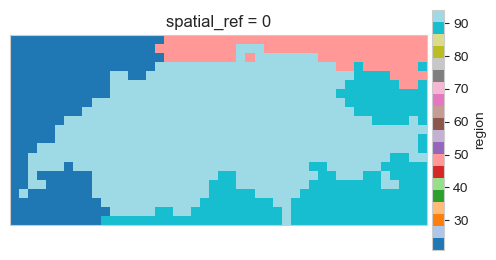

In [10]:
fg = mask_countries.plot(
    subplot_kws=dict(projection=ccrs.PlateCarree()),
    transform=ccrs.PlateCarree(),
    add_colorbar=True,
    cmap="tab20",
    cbar_kwargs={"pad": 0.01, "shrink": 0.65},
)

In [11]:
countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_frac_approx = countries.mask_3D_frac_approx(da_worldpop_coarse, wrap_lon=True)
weights = np.cos(np.deg2rad(da_worldpop_coarse.lat))

grouped_sum = da_worldpop_coarse.weighted(mask_frac_approx * weights).sum(
    dim=("lat", "lon")
)

# Display the result
for country in sorted(countries, key=lambda x: x.name):
    if country.number in grouped_sum.region:
        print(country.name, grouped_sum.sel(region=country.number).item() * 1e-6)

Austria 0.17876630971820176
France 1.1421685762415053
Germany 0.6615882054467711
Italy 0.530124835464986
Liechtenstein 0.013700402232254128
Switzerland 4.13452219861868


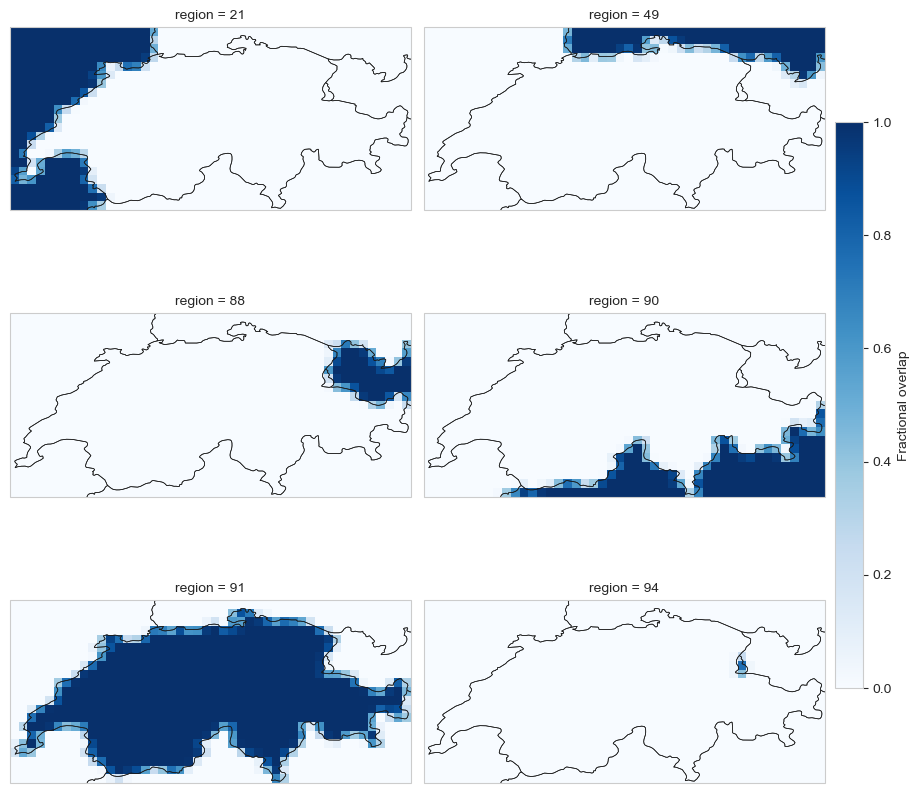

In [12]:
import cartopy.crs as ccrs

fg = mask_frac_approx.plot(
    subplot_kws=dict(projection=ccrs.PlateCarree()),
    col="region",
    col_wrap=2,
    transform=ccrs.PlateCarree(),
    add_colorbar=True,
    aspect=1.5,
    cmap="Blues",
    cbar_kwargs={"pad": 0.01, "shrink": 0.65},
)

fg.cbar.set_label("Fractional overlap")

for ax in fg.axs.flatten():
    regionmask.defined_regions.natural_earth_v5_0_0.countries_10.plot(
        ax=ax, add_label=False, line_kws={"lw": 0.5}
    )
    ax.set_extent(
        [
            extent_ch["lon_min"],
            extent_ch["lon_max"],
            extent_ch["lat_min"],
            extent_ch["lat_max"],
        ],
        ccrs.PlateCarree(),
    )

### LandScan

In [ ]:
da_landscan = sel_extent(
    rxr.open_rasterio(
        path_data_processed
        / "pop"
        / "landscan-global-2023-assets/landscan-global-2023.tif"
    ).rename({"x": "lon", "y": "lat"}),
    extent=extent,
)
da_landscan = da_landscan.where(da_landscan >= 0, np.nan)
# Print the DataArray
da_landscan

In [ ]:
da_landscan.plot()

In [ ]:
# Step 1: Coarsen (if needed to reduce data size)
da_landscan_coarse = da_landscan.coarsen(lat=10, lon=10, boundary="trim").sum()

# Step 2: Align to temperature dataset grid
da_landscan_coarse = da_landscan_coarse.interp(
    lat=ds_tas_bc.ds_data.lat, lon=ds_tas_bc.ds_data.lon, method="nearest"
)

In [ ]:
countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_countries = countries.mask(da_landscan, wrap_lon=True)

grouped_data = da_landscan.groupby(mask_countries)
grouped_sum = grouped_data.sum(dim=("lat", "lon"))

# Display the result
for country in sorted(countries, key=lambda x: x.name):
    if country.number in grouped_sum.mask:
        print(country.name, grouped_sum.sel(mask=country.number).item() * 1e-6)

In [ ]:
countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_countries = countries.mask(da_landscan_coarse, wrap_lon=True)

grouped_data = da_landscan_coarse.groupby(mask_countries)
grouped_sum = grouped_data.sum(dim=("lat", "lon"))

# Display the result
for country in sorted(countries, key=lambda x: x.name):
    if country.number in grouped_sum.mask:
        print(country.name, grouped_sum.sel(mask=country.number).item() * 1e-6)

# Heating and Cooling Degree Days

In [ ]:
extent_pop = {"lat_min": 29, "lat_max": 76, "lon_min": -11, "lon_max": 31}
da_worldpop_coarse = process_population_data(
    sel_extent(
        rxr.open_rasterio(
            Path(paths["path_data_processed"]) / "pop" / "ppp_2020_1km_Aggregated.tif"
        ).rename({"x": "lon", "y": "lat"}),
        extent=extent_pop,
    ),
    ds_tas_bc.ds_data,
    coarsen=True,
)

countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_countries_worldpop = countries.mask(da_worldpop_coarse, wrap_lon=True)
da_worldpop_coarse = normalize_population_data(
    da_worldpop_coarse, mask_countries_worldpop
).where(da_worldpop_coarse > 0, np.nan)

In [ ]:
ds_demand = compute_cdd_hdd_xr(
    ds_tas_bc.ds_data.tas,
    da_worldpop_coarse,
    parallelized=False,
)

In [ ]:
((mask_countries == 91) * ds_demand.HDD).groupby("time.year").sum(dim="time").sum(
    ["lat", "lon"]
).plot()
plt.title("HDD in Switzerland")
plt.show()

In [ ]:
((mask_countries == 91) * ds_demand.CDD).groupby("time.year").sum(dim="time").sum(
    ["lat", "lon"]
).plot()
plt.title("CDD in Switzerland")
plt.show()

# Precomputed HDD and CDD

In [8]:
reference_period = slice("1991", "2020")
future_period = slice("2021", "2050")

## Load data

In [9]:
path_hdd_cdd = path_energy_europe / "demand" / f"{climate_model_chain}_rcp85.zarr"

ds_demand_rcp85 = sel_extent(
    xr.open_zarr(path_hdd_cdd, chunks="auto"), extent=extent_ch
)
ds_demand_rcp26 = sel_extent(
    xr.open_zarr(
        path_hdd_cdd.with_name(path_hdd_cdd.name.replace("rcp85", "rcp26")),
        chunks="auto",
    ),
    extent=extent_ch,
)

In [10]:
ds_demand_rcp85_yearly = ds_demand_rcp85.resample(time="YE").sum(dim="time")
ds_demand_rcp26_yearly = ds_demand_rcp26.resample(time="YE").sum(dim="time")

In [11]:
ds_orog = sel_extent(
    xr.open_dataset(
        sorted(
            (
                path_data_processed
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / "fx"
            ).glob("*.nc")
        )[0]
    ),
    extent_ch,
)

In [12]:
extent_pop = {"lat_min": 29, "lat_max": 76, "lon_min": -11, "lon_max": 31}
da_worldpop_coarse = process_population_data(
    sel_extent(
        rxr.open_rasterio(
            Path(paths["path_data_processed"]) / "pop" / "ppp_2020_1km_Aggregated.tif"
        ).rename({"x": "lon", "y": "lat"}),
        extent=extent_pop,
    ),
    ds_demand_rcp85_yearly,
    coarsen=True,
)

countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_countries_worldpop = countries.mask(da_worldpop_coarse, wrap_lon=True)
da_worldpop_coarse = normalize_population_data(
    da_worldpop_coarse, mask_countries_worldpop
).where(da_worldpop_coarse > 0, np.nan)

In [13]:
gdf_regions_ch = gpd.read_file(
    path_data_processed / "maps" / "regions_ch" / "PRODREG.shp"
).to_crs("EPSG:4326")
regions_ch = regionmask.from_geopandas(gdf_regions_ch, names="ProdregN_3")
regions_ch_mask = regions_ch.mask(ds_orog.orog)

## EGU Plots

In [14]:
path_save_fig = path_figs / "demand"
path_save_fig.mkdir(parents=True, exist_ok=True)

In [32]:
fontsize_ticks = 12
fontsize_labels = 14
fontsize_title = 14

In [44]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature


def plot_mean_and_percentage_change(
    data_array,
    reference_period,
    future_period,
    orography,
    save_path,
    variable_name,
    model_chain,
    scenario,
    vmin=0,
    vmax=50,
    vmin_percent=-10,
    vmax_percent=10,
    save_plot=True,
):
    def setup_axes(ax, title):
        ax.set_title(title, fontsize=fontsize_title)  # Increase title font size
        ax.set_extent(
            [
                extent_ch["lon_min"],
                extent_ch["lon_max"],
                extent_ch["lat_min"],
                extent_ch["lat_max"],
            ],
            crs=ccrs.PlateCarree(),
        )
        ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
        ax.add_feature(cfeature.COASTLINE, edgecolor="black")
        ax.add_feature(cfeature.LAND, facecolor="lightgray")
        ax.add_feature(cfeature.OCEAN, facecolor="lightblue")

    # Calculate the mean values for the reference and future periods
    mean_reference = data_array.sel(time=reference_period).mean(dim="time")
    mean_future = data_array.sel(time=future_period).mean(dim="time")

    # Calculate the percentage change
    percentage_change = ((mean_future - mean_reference) / mean_reference + 0.001) * 100

    proj = ccrs.Mercator(central_longitude=8.0)

    # Plot the results
    fig, axes = plt.subplots(1, 2, figsize=(14, 7), subplot_kw={"projection": proj})

    cmap = "YlOrRd" if variable_name == "CDD" else "Blues"

    # Plot mean values for the reference period
    plot = mean_reference.plot(
        ax=axes[0],
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        cbar_kwargs={
            "label": "Cumulative Population-Weighted " + variable_name,
            "shrink": 0.5,
            "orientation": "vertical",  # Make colorbar vertical
            "pad": 0.05,
            "aspect": 20,  # Increase colorbar size
        },
        vmin=vmin,
        vmax=vmax,
    )
    setup_axes(
        axes[0],
        f"Mean Yearly Cumulative Population-Weighted {variable_name}\nReference Period ({reference_period.start}-{reference_period.stop})",
    )

    # Modify colorbar font sizes
    colorbar = plot.colorbar
    colorbar.ax.tick_params(labelsize=fontsize_labels)  # Set tick label size
    colorbar.set_label(colorbar.ax.get_ylabel(), fontsize=fontsize_labels, labelpad=10)

    # Plot percentage change
    plot = percentage_change.plot(
        ax=axes[1],
        cmap="coolwarm",
        transform=ccrs.PlateCarree(),
        cbar_kwargs={
            "label": "Percentage Change (%)",
            "shrink": 0.5,
            "orientation": "vertical",  # Make colorbar vertical
            "pad": 0.05,
            "aspect": 20,
        },
        vmin=vmin_percent,
        vmax=vmax_percent,
    )
    # Modify colorbar font sizes
    colorbar = plot.colorbar
    colorbar.ax.tick_params(labelsize=fontsize_ticks)  # Set tick label size
    colorbar.set_label(colorbar.ax.get_ylabel(), fontsize=fontsize_labels, labelpad=10)  # Set label font size

    setup_axes(
        axes[1],
        f"Percentage Change ({variable_name})\nFuture Period ({future_period.start}-{future_period.stop}) vs Reference Period ({reference_period.start}-{reference_period.stop})",
    )

    # Add elevation contours to both maps
    for ax in axes:
        cs = ax.contour(
            ds_orog.lon,
            ds_orog.lat,
            ds_orog.orog,
            levels=10,
            colors="grey",
            linewidths=0.3,
            transform=ccrs.PlateCarree(),
        )
        ax.clabel(cs, inline=True, fontsize=6, fmt="%d m")  # Adjust contour label font size

    for ax in axes:
        ax.tick_params(axis="both", which="major", labelsize=fontsize_labels)
        ax.tick_params(axis="both", which="minor", labelsize=fontsize_labels)

    plt.tight_layout()

    # Save the plot if save_plot is True
    if save_plot:
        save_path.mkdir(parents=True, exist_ok=True)
        plt.savefig(
            save_path
            / f"{model_chain}_{scenario}_{variable_name}_mean_and_percentage_change.png",
            dpi=300,
            bbox_inches="tight",
        )
    plt.show()

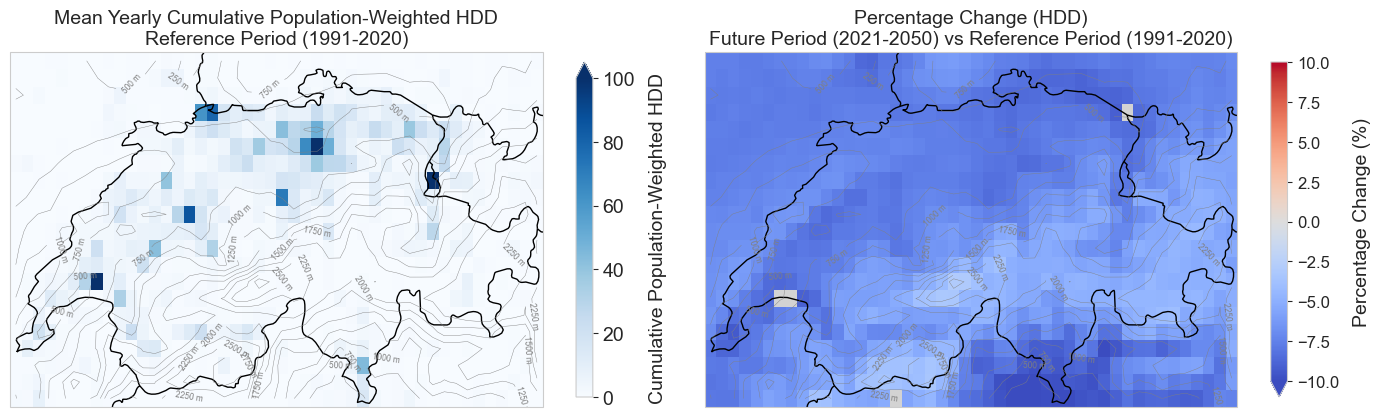

In [45]:
plot_mean_and_percentage_change(
    data_array=ds_demand_rcp85_yearly["HDD"],
    reference_period=reference_period,
    future_period=future_period,
    orography=ds_orog,
    save_path=path_save_fig,
    variable_name="HDD",
    model_chain=climate_model_chain,
    scenario=climate_scenario,
    vmin=0,
    vmax=100,
    save_plot=True,
)

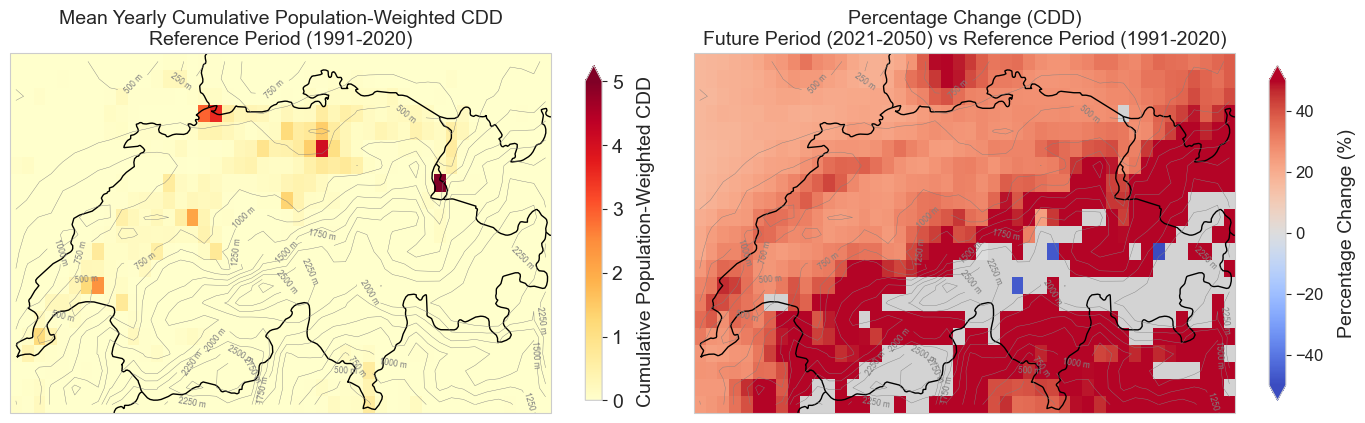

In [46]:
plot_mean_and_percentage_change(
    data_array=ds_demand_rcp85_yearly["CDD"],
    reference_period=reference_period,
    future_period=future_period,
    orography=ds_orog,
    save_path=path_save_fig,
    variable_name="CDD",
    model_chain=climate_model_chain,
    scenario=climate_scenario,
    vmin=0,
    vmax=5,
    vmin_percent=-50,
    vmax_percent=50,
    save_plot=True,
)

In [26]:
yearly_aggregated_reference_rcp85 = (
    ds_demand_rcp85.sel(time=reference_period)
    .resample(time="1YE")
    .sum()
    .groupby(regions_ch_mask)
    .sum(dim=("lat", "lon"))
)
yearly_aggregated_reference_rcp85["mask"] = gdf_regions_ch["ProdregN_3"].values

# Aggregate on a yearly level for each region for the future period (rcp26)
yearly_aggregated_reference_rcp26 = (
    ds_demand_rcp26.sel(time=reference_period)
    .resample(time="1YE")
    .sum()
    .groupby(regions_ch_mask)
    .sum(dim=("lat", "lon"))
)
yearly_aggregated_reference_rcp26["mask"] = gdf_regions_ch["ProdregN_3"].values


yearly_aggregated_future_rcp85 = (
    ds_demand_rcp85.sel(time=future_period)
    .resample(time="1YE")
    .sum()
    .groupby(regions_ch_mask)
    .sum(dim=("lat", "lon"))
)
yearly_aggregated_future_rcp85["mask"] = gdf_regions_ch["ProdregN_3"].values

# Aggregate on a yearly level for each region for the future period (rcp26)
yearly_aggregated_future_rcp26 = (
    ds_demand_rcp26.sel(time=future_period)
    .resample(time="1YE")
    .sum()
    .groupby(regions_ch_mask)
    .sum(dim=("lat", "lon"))
)
yearly_aggregated_future_rcp26["mask"] = gdf_regions_ch["ProdregN_3"].values

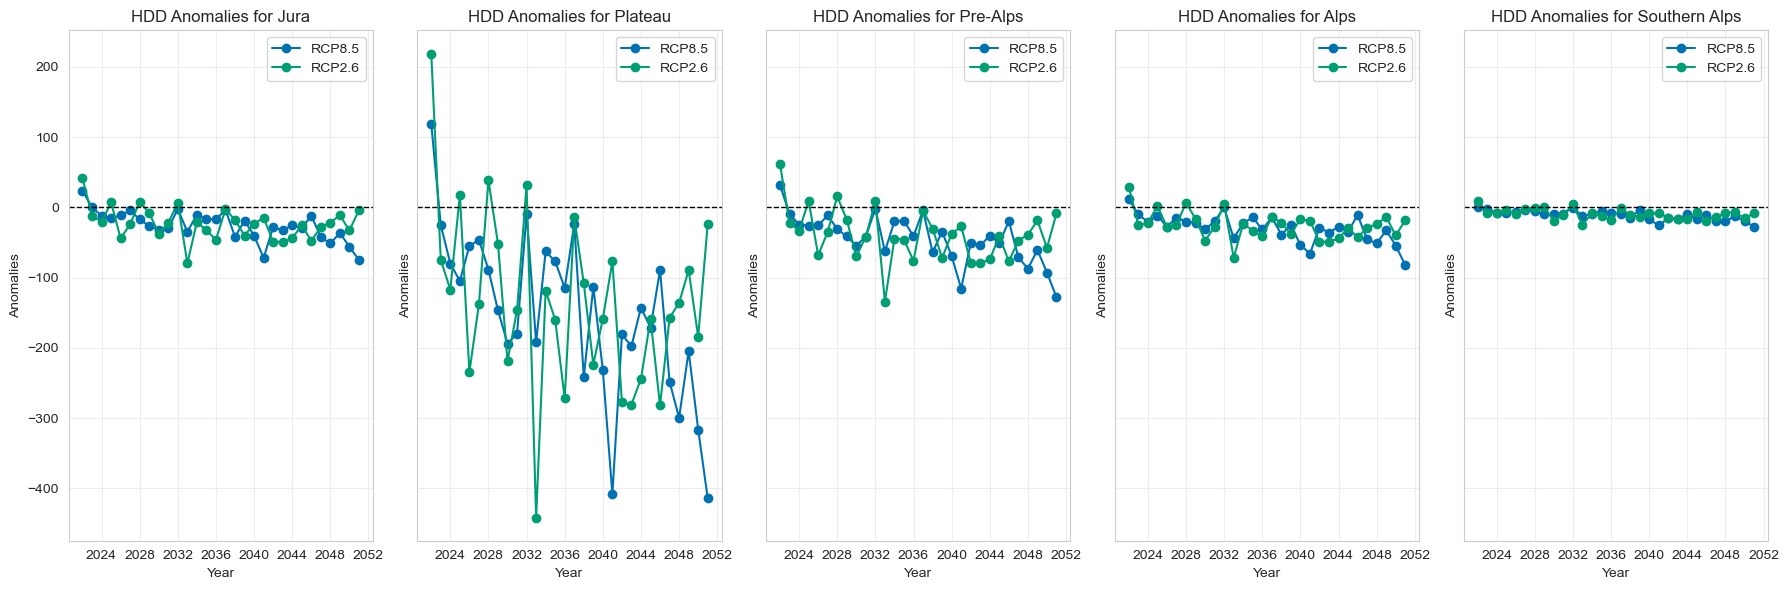

In [27]:
regions_to_plot = ["Plateau", "Alps"]
regions_to_plot = yearly_aggregated_future_rcp85["mask"].values
colors = ["#0072B2", "#009E73"]

fig, axes = plt.subplots(1, 5, figsize=(18, 6), sharey=True)
for i, region in enumerate(regions_to_plot):
    # RCP85
    anomalies_rcp85 = (
        yearly_aggregated_future_rcp85["HDD"].sel(mask=region)
        - yearly_aggregated_reference_rcp85["HDD"].sel(mask=region).mean(dim="time")
    )
    anomalies_rcp85.plot(ax=axes[i], marker="o", label="RCP8.5", color=colors[0])

    # RCP26
    anomalies_rcp26 = (
        yearly_aggregated_future_rcp26["HDD"].sel(mask=region)
        - yearly_aggregated_reference_rcp26["HDD"].sel(mask=region).mean(dim="time")
    )
    anomalies_rcp26.plot(ax=axes[i], marker="o", label="RCP2.6", color=colors[1])

    # Highlight the 0 line
    axes[i].axhline(0, color="black", linestyle="--", linewidth=1)

    axes[i].set_title(f"HDD Anomalies for {region}")
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Anomalies")
    axes[i].legend()

plt.tight_layout()
plt.show()

/tmp/ipykernel_44731/357221635.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_labels, rotation=0, ha="center", fontsize=fontsize_labels)


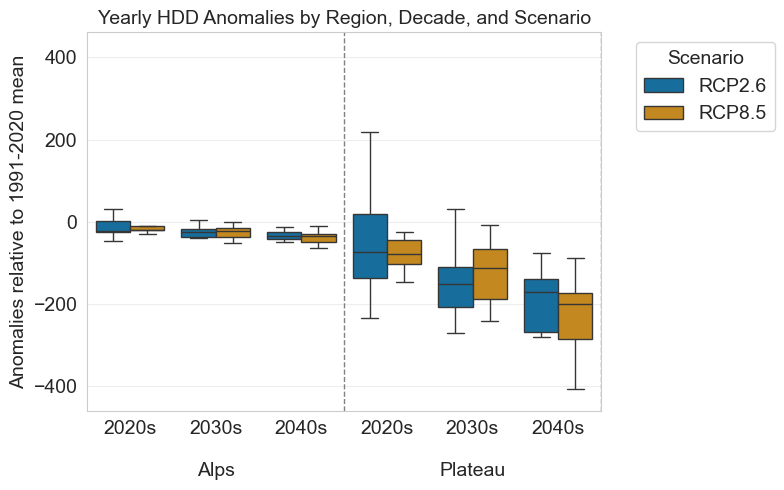

In [47]:
regions_to_plot = ["Plateau", "Alps"]
colors = sns.color_palette("colorblind")[0:2]

# Add RCP26 data to the DataFrame
selected_var = "HDD"
anomalies_rcp26 = (
    yearly_aggregated_future_rcp26[selected_var]
    - yearly_aggregated_reference_rcp26[selected_var].mean(dim="time")
)
anomalies_rcp26 = anomalies_rcp26.assign_coords(
    decade=(anomalies_rcp26["time"].dt.year // 10) * 10
)
df_rcp26 = anomalies_rcp26.to_dataframe().reset_index()
df_rcp26["scenario"] = "RCP2.6"

# Add RCP85 data to the DataFrame
anomalies_rcp85 = (
    yearly_aggregated_future_rcp85[selected_var]
    - yearly_aggregated_reference_rcp85[selected_var].mean(dim="time")
)
anomalies_rcp85 = anomalies_rcp85.assign_coords(
    decade=(anomalies_rcp85["time"].dt.year // 10) * 10
)
df_rcp85 = anomalies_rcp85.to_dataframe().reset_index()
df_rcp85["scenario"] = "RCP8.5"


# Combine the data
df_combined = pd.concat([df_rcp26, df_rcp85])
# Clean and prep
df_combined["decade_str"] = df_combined["decade"].astype(str) + "s"
df_combined["region"] = df_combined["mask"].astype(str)

# Filter data to include only relevant decades
plot_df = df_combined[(df_combined["decade"] < 2050) & (df_combined["region"].isin(["Plateau", "Alps"]))].copy()
vmin = plot_df[selected_var].min()
vmin = min(vmin, -plot_df[selected_var].max()) - 20
vmax = plot_df[selected_var].max()
vmax = max(vmax, -plot_df[selected_var].min()) + 20

# Sort the values by region and decade
# Create combined column for region and decade, so all decades of the same region are next to each other
plot_df["region_decade"] = plot_df["decade_str"] + " - " + plot_df["region"]

# Sort the values by region and decade
plot_df = plot_df.sort_values(by=["region", "decade"])

# Plot the boxplot
plt.figure(figsize=(8, 5))
ax = sns.boxplot(
    data=plot_df,
    x="region_decade",  # Use the combined column for region and decade
    y=selected_var,
    hue="scenario",
    palette=colors,
    dodge=True,
    showfliers=False
)
ax.set_ylim(vmin, vmax)

# Create a custom x-tick label that shows only the central decade
xticks = ax.get_xticks()  # Get the positions of the ticks
xtick_labels = ax.get_xticklabels()

# Only label the central decade for each region, add region names underneath
new_labels = []
for i, label in enumerate(xtick_labels):
    label_text = label.get_text()  # Extract the text from the Text object
    # Split the label to get the decade and region
    decade, region = label_text.split(" - ")

    # Label only the central decade for each region, and place the region name underneath
    if (i + 2) % 3 == 0:  # Assuming even positions correspond to the central decade
        new_labels.append(f"{decade}\n\n{region}")
    else:
        new_labels.append(f"{decade}")

ax.set_xticklabels(new_labels, rotation=0, ha="center", fontsize=fontsize_labels)
# Add vertical lines between regions
region_boundaries = [i + 0.5 for i in range(2, len(xticks), 3)]  # Positions between regions
for boundary in region_boundaries:
    plt.axvline(x=boundary, color='gray', linestyle='--', linewidth=1)

ax.tick_params(axis="both", which="major", labelsize=fontsize_labels)
ax.tick_params(axis="both", which="minor", labelsize=fontsize_labels)

plt.title("Yearly HDD Anomalies by Region, Decade, and Scenario", fontsize=fontsize_labels)
plt.xlabel("")
plt.ylabel("Anomalies relative to 1991-2020 mean", fontsize=fontsize_labels)
plt.legend(title="Scenario", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=fontsize_labels, title_fontsize=fontsize_labels)

plt.tight_layout()

path_save_fig.mkdir(parents=True, exist_ok=True)
plt.savefig(
    path_save_fig
    / f"{climate_model_chain}_{selected_var}_yearly_anomalies_region_decade.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

/tmp/ipykernel_44731/3661332481.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_labels, rotation=0, ha="center", fontsize=fontsize_labels)


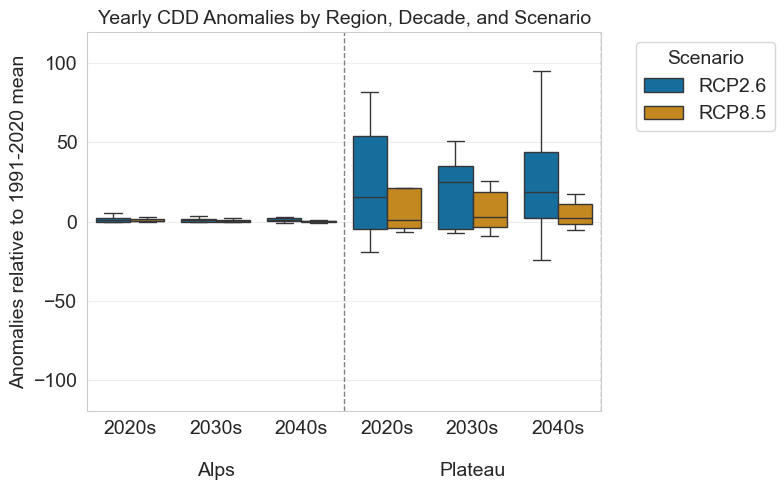

In [48]:
regions_to_plot = ["Plateau", "Alps"]
colors = sns.color_palette("colorblind")[0:2]

# Add RCP26 data to the DataFrame
selected_var = "CDD"
anomalies_rcp26 = (
    yearly_aggregated_future_rcp26[selected_var]
    - yearly_aggregated_reference_rcp26[selected_var].mean(dim="time")
)
anomalies_rcp26 = anomalies_rcp26.assign_coords(
    decade=(anomalies_rcp26["time"].dt.year // 10) * 10
)
df_rcp26 = anomalies_rcp26.to_dataframe().reset_index()
df_rcp26["scenario"] = "RCP2.6"

# Add RCP85 data to the DataFrame
anomalies_rcp85 = (
    yearly_aggregated_future_rcp85[selected_var]
    - yearly_aggregated_reference_rcp85[selected_var].mean(dim="time")
)
anomalies_rcp85 = anomalies_rcp85.assign_coords(
    decade=(anomalies_rcp85["time"].dt.year // 10) * 10
)
df_rcp85 = anomalies_rcp85.to_dataframe().reset_index()
df_rcp85["scenario"] = "RCP8.5"


# Combine the data
df_combined = pd.concat([df_rcp26, df_rcp85])
# Clean and prep
df_combined["decade_str"] = df_combined["decade"].astype(str) + "s"
df_combined["region"] = df_combined["mask"].astype(str)

# Filter data to include only relevant decades
plot_df = df_combined[(df_combined["decade"] < 2050) & (df_combined["region"].isin(["Plateau", "Alps"]))].copy()
vmin = plot_df[selected_var].min()
vmin = min(vmin, -plot_df[selected_var].max()) - 20
vmax = plot_df[selected_var].max()
vmax = max(vmax, -plot_df[selected_var].min()) + 20

# Sort the values by region and decade
# Create combined column for region and decade, so all decades of the same region are next to each other
plot_df["region_decade"] = plot_df["decade_str"] + " - " + plot_df["region"]

# Sort the values by region and decade
plot_df = plot_df.sort_values(by=["region", "decade"])

# Plot the boxplot
plt.figure(figsize=(8, 5))
ax = sns.boxplot(
    data=plot_df,
    x="region_decade",  # Use the combined column for region and decade
    y=selected_var,
    hue="scenario",
    palette=colors,
    dodge=True,
    showfliers=False
)
ax.set_ylim(vmin, vmax)

# Create a custom x-tick label that shows only the central decade
xticks = ax.get_xticks()  # Get the positions of the ticks
xtick_labels = ax.get_xticklabels()

# Only label the central decade for each region, add region names underneath
new_labels = []
for i, label in enumerate(xtick_labels):
    label_text = label.get_text()  # Extract the text from the Text object
    # Split the label to get the decade and region
    decade, region = label_text.split(" - ")

    # Label only the central decade for each region, and place the region name underneath
    if (i + 2) % 3 == 0:  # Assuming even positions correspond to the central decade
        new_labels.append(f"{decade}\n\n{region}")
    else:
        new_labels.append(f"{decade}")

ax.set_xticklabels(new_labels, rotation=0, ha="center", fontsize=fontsize_labels)
# Add vertical lines between regions
region_boundaries = [i + 0.5 for i in range(2, len(xticks), 3)]  # Positions between regions
for boundary in region_boundaries:
    plt.axvline(x=boundary, color='gray', linestyle='--', linewidth=1)

ax.tick_params(axis="both", which="major", labelsize=fontsize_labels)
ax.tick_params(axis="both", which="minor", labelsize=fontsize_labels)

plt.title("Yearly CDD Anomalies by Region, Decade, and Scenario", fontsize=fontsize_labels)
plt.xlabel("")
plt.ylabel("Anomalies relative to 1991-2020 mean", fontsize=fontsize_labels)
plt.legend(title="Scenario", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=fontsize_labels, title_fontsize=fontsize_labels)

plt.tight_layout()

path_save_fig.mkdir(parents=True, exist_ok=True)
plt.savefig(
    path_save_fig
    / f"{climate_model_chain}_{selected_var}_yearly_anomalies_region_decade.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()